In [36]:
import torch
import torch.nn as nn
from torchvision import transforms
import matplotlib.pyplot as plt
from tqdm import tqdm
from IPython.display import clear_output
from torch.utils.data import Dataset, DataLoader
import os
from glob import glob
from PIL import Image
from utils import moving_average

In [37]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print(f"Using device: {device}")

Using device: cuda


In [38]:
img_type = "sat"   # choisir entre sat et annotations

if img_type == "sat":
    path_type = "S2L2A"
elif img_type == "annotations":
    path_type = "Esri10_LC"
else:
    print("Erreur, img_type non reconnu")

In [39]:
batch_size = 512
learning_rate = 3e-4
n_epochs = 9000
n_classes = 5
crop_size = 224

In [ ]:
class ImageDataset(Dataset):

    def __init__(self, root_dir, transform=None):
        self.transform = transform

        # get all image paths
        self.img_paths = []

        for path in glob(os.path.join(root_dir, "**", f"*{path_type}*"), recursive=True):
            if path.lower().endswith((".jpg", ".jpeg", ".png")):
                img_path = path

                path_to_img_gra = img_path.replace(path_type, "GRA")
                path_to_img_del = img_path.replace(path_type, "DEL")
                if os.path.exists(path_to_img_gra):
                    img_burn_path = path_to_img_gra
                elif os.path.exists(path_to_img_del):
                    img_burn_path = path_to_img_del
                else:
                    print("********** image brûlée non trouvée *********")
                    continue

                self.img_paths.append((img_path, img_burn_path))

        # loads images into memory
        self.data = []

        for img_path, img_burn_path in self.img_paths:
            img = Image.open(img_path).convert("RGB")
            img_burn = Image.open(img_burn_path).convert("RGB")
            assert img.size == img_burn.size, f"Image size mismatch: {img_path} and {img_burn_path}"
            img_tensor = transforms.ToTensor()(img)
            img_burn_tensor = transforms.ToTensor()(img_burn)
            self.data.append((img_tensor, img_burn_tensor))

        print(f"[INFO] Dataset chargé en mémoire : {len(self.data)} images, "
              f"{sum(img[0].element_size() * img[0].nelement() for img in self.data) / 1e6:.1f} Mo RAM")


    def __len__(self):
        return len(self.img_paths)
    

    def pixel_to_label(self, tensor):
        pixel = tuple((tensor*255).long().tolist())   # Convert tensor to tuple

        mapping = {
            (0, 0, 0): 0,  # no visible damage
            (181, 254, 142): 1,  # negligible to slight damage
            (254, 217, 142): 2,  # moderate damage
            (254, 153, 41): 3,  # high damage
            (204, 76, 2): 4,  # destruction
            (255, 255, 255): 0  # problème de couleur avec le 134e masque de brûlé
        }
        if pixel not in mapping:
            print(f"Pixel inconnu : {pixel}")
            return None

        return mapping[pixel]


    def random_crop_with_coords(self, img):
        _, h, w = img.shape

        if crop_size > h or crop_size > w:
            raise ValueError("Le crop est plus grand que l'image")

        top = torch.randint(0, h - crop_size + 1, (1,)).item()
        left = torch.randint(0, w - crop_size + 1, (1,)).item()

        cropped = img[:, top:top+crop_size, left:left+crop_size]

        return cropped, (top, left)


    def __getitem__(self, idx):
        img_tensor, img_burn_tensor = self.data[idx]

        cropped_tensor, (top_coo, left_coo) = self.random_crop_with_coords(img_tensor)

        middle_pixel = img_burn_tensor[:, top_coo + crop_size // 2, left_coo + crop_size // 2]

        label = self.pixel_to_label(middle_pixel)

        if self.transform:
            cropped_tensor = self.transform(cropped_tensor)

        return cropped_tensor, label


transform = transforms.Compose([
    # transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

train_dataset = ImageDataset(root_dir="data/dataset/train", transform=transform)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = ImageDataset(root_dir="data/dataset/val", transform=transform)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=True)

train_iterator = iter(train_loader)
val_iterator = iter(val_loader)

[INFO] Dataset chargé en mémoire : 281 images, 5722.9 Mo RAM
[INFO] Dataset chargé en mémoire : 53 images, 1246.7 Mo RAM


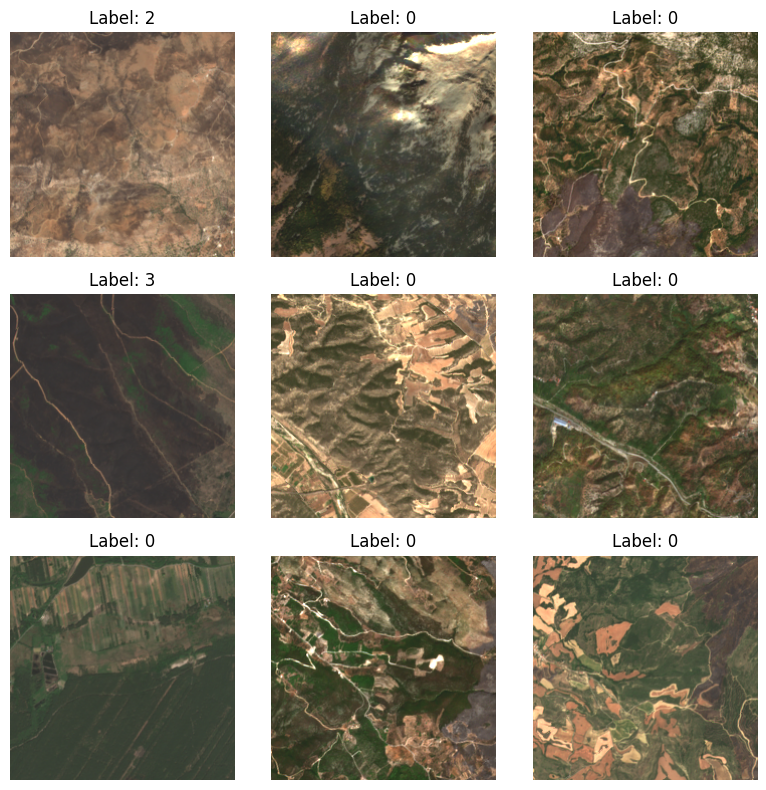

In [41]:
# Afficher une grille 3x3 d'exemples
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
for i in range(3):
    for j in range(3):
        img, label = next(iter(train_loader))
        axes[i, j].imshow((img[0].permute(1, 2, 0).numpy() + 1)/2)
        axes[i, j].set_title(f"Label: {label[0]}")
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

In [42]:
from torchvision.models import resnet18
from torchvision.models import ResNet18_Weights   # Import des poids officiels

model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)   # Charger un modèle préentraîné

# # différentes couches du modèle
# for name, layer in model.named_children():
#     print(name, ":", layer)

# remplacer la dernière couche pour avoir le bon nombre de classe et pas les 1000 de ImageNet
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, n_classes)

total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters in the model: {total_params/1e6:.6f} million")

Total parameters in the model: 11.179077 million


In [43]:
model = model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
criterion = nn.CrossEntropyLoss()

train_loss_list, val_loss_list, test_loss_list = [], [], []
train_acc_list, val_acc_list, test_acc_list = [], [], []

In [44]:
def get_accuracy(split, iterator):
    if split == "train":
        loader = train_loader
    elif split == "val":
        loader = val_loader
    # elif split == "test":
    #     loader = test_loader
    else:
        print("split non définit")
        return None

    model.eval()
    with torch.no_grad():
        try:
            x, y = next(iterator)
        except StopIteration:
            iterator = iter(loader)
            x, y = next(iterator)
        x, y = x.to(device), y.to(device)
        y_hat = model(x)
        probs = torch.softmax(y_hat, dim=1)
        preds = torch.argmax(probs, dim=1)
        n_correct = (preds.view(-1) == y.view(-1)).float().sum().item()
        n_total = y.shape[0]
    accuracy = n_correct / n_total
    model.train()
    return accuracy, iterator

moyenne sur les 100 dernières valeurs:   train_acc: 0.5302491188049316   val_acc: 0.6603773832321167


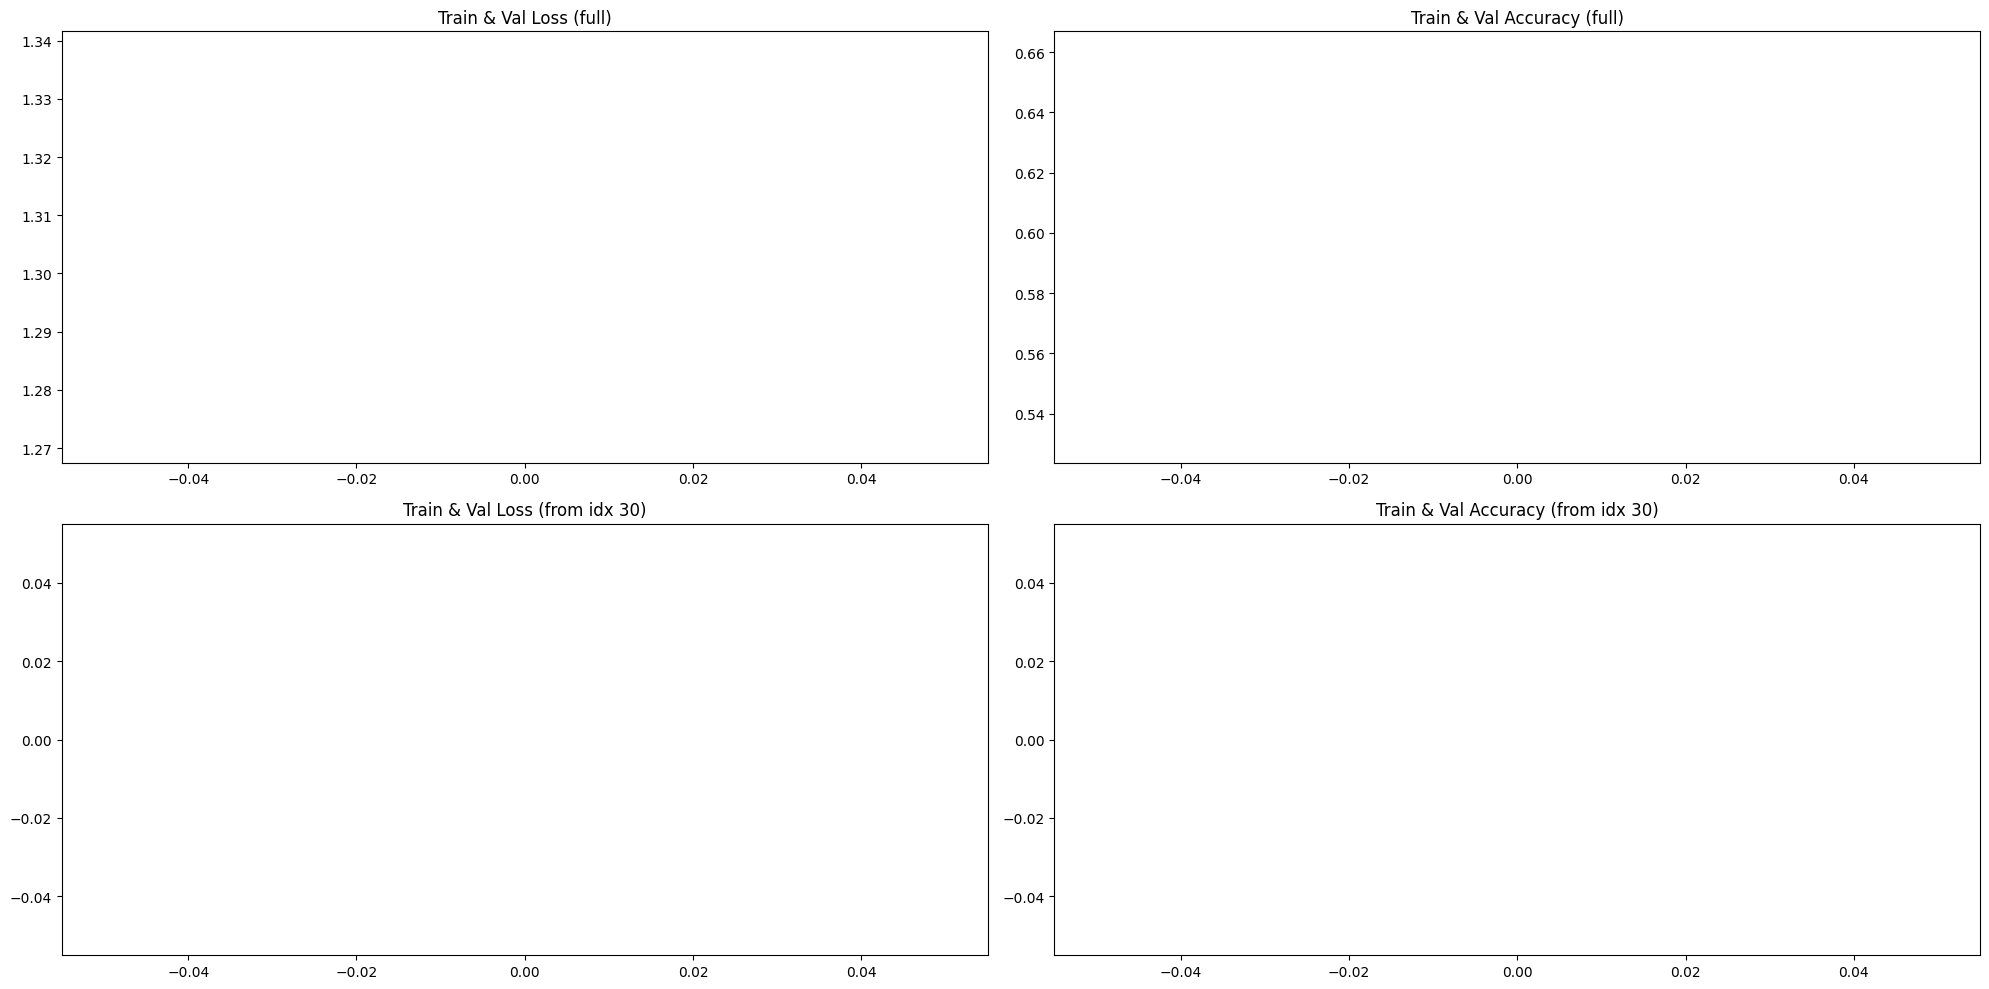

  0%|          | 30/9000 [00:20<1:43:36,  1.44it/s]


KeyboardInterrupt: 

In [45]:
for epoch in tqdm(range(n_epochs)):
    for i, (imgs, classes) in enumerate(train_loader):

        imgs, classes = imgs.to(device), classes.to(device)

        output = model(imgs)
        loss = criterion(output, classes)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()



        if epoch % 10 == 0 and i % 999 == 0:
            train_loss_list.append(loss.item())

            # get val loss
            model.eval()
            with torch.no_grad():
                try:
                    imgs, classes = next(val_iterator)
                except StopIteration:
                    val_iterator = iter(val_loader)
                    imgs, classes = next(val_iterator)
                imgs, classes = imgs.to(device), classes.to(device)
                output = model(imgs)
                val_loss = criterion(output, classes)
                val_loss_list.append(val_loss.item())
            model.train()

            # get accuracy
            train_acc, train_iterator = get_accuracy("train", train_iterator)
            val_acc, val_iterator = get_accuracy("val", val_iterator)
            train_acc_list.append(train_acc)
            val_acc_list.append(val_acc)



    
    if epoch % 900 == 0:

        train_loss_list_smoothed = moving_average(train_loss_list)
        val_loss_list_smoothed = moving_average(val_loss_list)
        train_acc_list_smoothed = moving_average(train_acc_list)
        val_acc_list_smoothed = moving_average(val_acc_list)

        clear_output(wait=True)  # efface l'ancien plot

        print(f"moyenne sur les 100 dernières valeurs:   train_acc: {torch.tensor([train_acc_list_smoothed[-100:]]).mean()}   val_acc: {torch.tensor([val_acc_list_smoothed[-100:]]).mean()}")

        plt.figure(figsize=(20, 10))  # plus grand pour 4 sous-plots

        # 1er plot (train+val loss, full)
        plt.subplot(2, 2, 1)
        plt.plot(train_loss_list, c="blue", alpha=0.3)
        plt.plot(train_loss_list_smoothed, c="blue", linestyle='--')
        plt.plot(val_loss_list, c="red", alpha=0.3)
        plt.plot(val_loss_list_smoothed, c="red", linestyle='--')
        plt.title("Train & Val Loss (full)")

        # 2e plot (train+val acc, full)
        plt.subplot(2, 2, 2)
        plt.plot(train_acc_list, c="blue", alpha=0.3)
        plt.plot(train_acc_list_smoothed, c="blue", linestyle='--')
        plt.plot(val_acc_list, c="red", alpha=0.3)
        plt.plot(val_acc_list_smoothed, c="red", linestyle='--')
        plt.title("Train & Val Accuracy (full)")

        # 3e plot (train+val loss, from index 30)
        plt.subplot(2, 2, 3)
        plt.plot(train_loss_list[30:], c="blue", alpha=0.3)
        plt.plot(train_loss_list_smoothed[30:], c="blue", linestyle='--')
        plt.plot(val_loss_list[30:], c="red", alpha=0.3)
        plt.plot(val_loss_list_smoothed[30:], c="red", linestyle='--')
        plt.title("Train & Val Loss (from idx 30)")

        # 4e plot (train+val acc, from index 30)
        plt.subplot(2, 2, 4)
        plt.plot(train_acc_list[30:], c="blue", alpha=0.3)
        plt.plot(train_acc_list_smoothed[30:], c="blue", linestyle='--')
        plt.plot(val_acc_list[30:], c="red", alpha=0.3)
        plt.plot(val_acc_list_smoothed[30:], c="red", linestyle='--')
        plt.title("Train & Val Accuracy (from idx 30)")

        plt.tight_layout()  # ajuste l'espacement
        plt.show()
